# MarketSim M1 - 01 Reading and profiling
Team: _fill in_  |  Student: Ahmed Shawky Moubarak (70-40377)

Goal of this notebook: read every file in its own format, **profile it, and say what is wrong before anything is fixed**.
Each problem has an id (P01, P02, ...) that is used again in `docs/data_quality_findings.md`.
The fixing code is not here. It lives in the module `marketsim/` (functions), and `run_pipeline.py` runs it.

In [1]:
import sys, json, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")            # work from the M1 folder so the relative paths of the module are right
sys.path.insert(0, ".")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from marketsim import config as C, readers as R
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RAW = C.RAW_DIR
print("raw folder:", RAW)

raw folder: data/raw/marketsim-pack-v1


## 1. Reference files (CSV, read with explicit types)

In [2]:
sym = R.read_symbols(); hist = R.read_symbol_history(); cal = R.read_calendar()
print(sym.shape, hist.shape, cal.shape)
sym.dtypes

(31, 7) (3, 5) (129, 6)


security_id             str
ticker                  str
company_name            str
sector                  str
listing_date            str
delisting_date          str
shares_outstanding    Int64
dtype: object

In [3]:
# P01: security_id must be a primary key
print("rows:", len(sym), " distinct security_id:", sym.security_id.nunique())
print(sym[sym.security_id.duplicated(keep=False)].to_string())
# P02: sector labels
print(sym.sector.value_counts())
# P03: symbols.csv says VALX is Energy, but the history says it became Technology on 2025-05-01
print(hist.to_string())
print(sym[sym.security_id.isin(hist.security_id)][["security_id","ticker","sector","shares_outstanding"]].to_string())

rows: 31  distinct security_id: 30
   security_id ticker        company_name      sector listing_date delisting_date  shares_outstanding
8       SEC009   ISTK  Iston Therapeutics  Healthcare   2022-09-03            NaN           320000000
30      SEC009   istk  ISTON THERAPEUTICS  Healthcare   2022-09-03            NaN           320000000
sector
Healthcare                6
Financials                5
Energy                    5
Industrials               5
Consumer                  5
Technology                4
Information Technology    1
Name: count, dtype: int64
  security_id         change_type  old_value   new_value effective_date
0      SEC017              ticker       ORBT        ORBX     2025-03-17
1      SEC022              sector     Energy  Technology     2025-05-01
2      SEC010  shares_outstanding  207000000   414000000     2025-04-01
   security_id ticker       sector  shares_outstanding
9       SEC010   JORV       Energy           414000000
16      SEC017   ORBX  Industria

In [4]:
# listing / delisting windows (these decide which symbols are expected on which day)
print(sym[(sym.listing_date >= "2025-01-02") | sym.delisting_date.notna()][["security_id","ticker","listing_date","delisting_date"]])
c = cal.copy(); c["is_trading_day"] = c.is_trading_day.str.lower().eq("true")
print(c.groupby(["is_trading_day","session_open","session_close"], dropna=False).size())
print(c[~c.is_trading_day | (c.session_close != "16:00")][["date","is_trading_day","session_close","note"]].to_string())
print("timezones:", c.timezone.unique(), "| dates", c.date.min(), "->", c.date.max(), "| duplicated dates:", c.date.duplicated().sum())

   security_id ticker listing_date delisting_date
24      SEC025   YARL   2023-01-03     2025-04-30
28      SEC029   CELK   2025-03-03            NaN
29      SEC030   DOVV   2025-05-12            NaN
is_trading_day  session_open  session_close
False           NaN           NaN                5
True            09:30         13:00              1
                              16:00            123
dtype: int64
           date  is_trading_day session_close              note
12   2025-01-20           False           NaN  Exchange holiday
32   2025-02-17           False           NaN   Presidents' Day
75   2025-04-17            True         13:00       early close
76   2025-04-18           False           NaN       Good Friday
102  2025-05-26           False           NaN      Memorial Day
120  2025-06-19           False           NaN        Juneteenth
timezones: <ArrowStringArray>
['America/New_York']
Length: 1, dtype: str | dates 2025-01-02 -> 2025-07-01 | duplicated dates: 0


## 2. Nested JSON (flattened)

In [5]:
runs = R.read_runs()
print(runs[["run_id","config_version","created_at","seed","parameters.volatility.sigma_annual",
            "parameters.news_memory.alpha","parameters.news_memory.gamma","parameters.intraday.open_boost"]].to_string())

      run_id config_version                 created_at     seed  parameters.volatility.sigma_annual  parameters.news_memory.alpha  parameters.news_memory.gamma  parameters.intraday.open_boost
0  RUN-2025A          1.4.0  2025-07-02T08:00:00+02:00  8522640                                0.18                          0.03                           0.6                             1.2
1  RUN-2025B          1.4.1  2025-07-02T08:00:00+02:00  7737823                                0.18                          0.33                           0.0                             0.0
2  RUN-2025C          1.4.0  2025-07-02T08:00:00+02:00  8325121                               18.00                          0.03                           0.6                             1.2
3  RUN-2025B          1.4.1  2025-07-03T11:20:00+02:00  7737823                                0.18                          0.33                           0.0                             0.0


* **P04** `RUN-2025B` is exported twice (config 1.4.1, created 2025-07-02 and again 2025-07-03). `run_id` is not unique.
* **P05** `RUN-2025C` has `sigma_annual = 18.0` while the others have `0.18` (a percent typed as a fraction).
* RUN-2025B was configured on purpose with no intraday boost and `gamma = 0` (no leverage effect), so it should fail those certification checks later. That is not a data error.

In [6]:
ev = R.read_events()
print(ev.shape, ev.type.value_counts().to_dict())
print(ev[ev.type != "earnings"].to_string())
print("UTC offsets in event times:", ev.time.str[-6:].value_counts().to_dict())
known = set(sym.ticker)
print("event tickers not in symbols.csv (they use the OLD ticker):", sorted(set(ev.ticker) - known))
print("event_id unique:", ev.event_id.is_unique)

(62, 8) {'earnings': 60, 'halt': 1, 'split': 1}
   event_id   type                       time ticker session  duration_minutes ratio  source_row
11   EV0012   halt  2025-02-12T11:00:00-05:00   GALR     NaN              45.0   NaN          11
31   EV0032  split  2025-04-01T09:30:00-04:00   JORV     NaN               NaN   2:1          31
UTC offsets in event times: {'-04:00': 41, '-05:00': 21}
event tickers not in symbols.csv (they use the OLD ticker): ['ORBT']
event_id unique: True


* **P06** `events.json` refers to `ORBT`, the ticker before the 2025-03-17 rename, so a ticker must be resolved as of the event date.
* The offsets are -05:00 / -04:00, so event times follow New York daylight saving; they have to be converted, not read as naive.
* Only two non-earnings events exist: a 45-minute halt of GALR on 12 Feb and a 2:1 split of JORV on 1 Apr.

## 3. Minute bars (Parquet, schema checked)

In [7]:
import pyarrow.parquet as pq
f = pq.ParquetFile(RAW / "bars_1m.parquet")
print(f.schema_arrow); print("rows:", f.metadata.num_rows, "row groups:", f.metadata.num_row_groups)
bars = R.read_bars()   # raises if the schema is different from the contract
print(bars.shape)
pd.DataFrame({"nulls": bars.isna().sum(), "null_rate": (bars.isna().mean()*100).round(4)})

run_id: string
ticker: string
ts: string
open: double
high: double
low: double
close: double
volume: int64
received_at: timestamp[ms, tz=UTC]
rows: 4276175 row groups: 5


(4276175, 10)


,nulls,null_rate
run_id,0,0.00
ticker,0,0.00
ts,0,0.00
open,0,0.00
high,0,0.00
low,0,0.00
close,854,0.02
volume,0,0.00
received_at,0,0.00
source_row,0,0.00


In [8]:
print(bars.run_id.value_counts())
print("distinct tickers:", bars.ticker.nunique())
print("not in symbols.csv (and not INDEX):", sorted(set(bars.ticker) - set(sym.ticker) - {"INDEX"}))
print("received_at:", bars.received_at.min(), "->", bars.received_at.max())
bars[["open","high","low","close","volume"]].describe().T

run_id
RUN-2025A    1431358
RUN-2025B    1424991
RUN-2025C    1419566
RUN-TEST         260
Name: count, dtype: int64
distinct tickers: 33


not in symbols.csv (and not INDEX): ['ORBT', 'ZZZT']
received_at: 2025-01-02 14:31:00+00:00 -> 2025-06-30 20:28:50+00:00


,count,mean,std,min,25%,50%,75%,max
open,4276175.0,149.361520,183.483391,4.81,63.54,113.11,157.54,1483.31
high,4276175.0,149.514873,183.603075,4.84,63.59,113.25,157.75,1483.84
low,4276175.0,149.208318,183.363950,4.80,63.48,112.97,157.35,1482.76
close,4275321.0,149.359425,183.479766,4.81,63.54,113.11,157.54,1483.31
volume,4276175.0,8358.851333,25639.986706,-47568.00,1599.00,2825.00,5232.00,13208790.00


* **P07** `RUN-TEST` (260 rows) is not in `sim_runs.json`.
* **P08** `ZZZT` is not a company; `ORBT` is only the OLD ticker of `ORBX` (same security, `SEC017`).

In [9]:
# P09: the ts column is a raw string and not one single format
shape = bars.ts.str.replace(r"\d", "9", regex=True)
tab = pd.crosstab(bars.run_id, shape)
tab

ts,99/99/9999 99:99,9999-99-99 99:99:99,9999-99-99T99:99:99Z,not-a-time
run_id,,,,
RUN-2025A,45,1431262,0,51
RUN-2025B,59,52,1424849,31
RUN-2025C,55,1419478,0,33
RUN-TEST,0,260,0,0


In [10]:
# what does each format mean?  look at the clock of each one
plain = bars[shape == "9999-99-99 99:99:99"].ts.str.slice(11, 16)
zulu  = bars[shape == "9999-99-99T99:99:99Z"].ts.str.slice(11, 16)
print("plain local format  first/last HH:MM:", plain.min(), plain.max())
print("Z format            first/last HH:MM:", zulu.min(), zulu.max(), " <- 14:30Z = 09:30 New York (UTC)")
print("the 'Z' format belongs to:", bars[shape == "9999-99-99T99:99:99Z"].run_id.unique())
print(bars[shape.str.contains("/")].ts.value_counts())
print("rows with a different value of ts but the same format are all one string; their prices span the window:")
s = bars[shape.str.contains("/")]; print(s[s.ticker == "ARVT"][["run_id","ts","close","received_at"]].head(6).to_string())
print(bars[shape == "not-a-time"].shape[0], "rows 'not-a-time'; impossible date example:", bars[bars.ts.str.startswith("2025-02-30")].ts.iloc[0], "x", bars.ts.str.startswith("2025-02-30").sum())

plain local format  first/last HH:MM: 09:25 15:59
Z format            first/last HH:MM: 13:25 20:59  <- 14:30Z = 09:30 New York (UTC)
the 'Z' format belongs to: <ArrowStringArray>
['RUN-2025B']
Length: 1, dtype: str


ts
31/03/2025 10:15    159
Name: count, dtype: int64
rows with a different value of ts but the same format are all one string; their prices span the window:
            run_id                ts   close               received_at
9247     RUN-2025A  31/03/2025 10:15  133.83 2025-02-04 19:05:01+00:00
31597    RUN-2025A  31/03/2025 10:15  107.14 2025-04-29 16:25:02+00:00
39356    RUN-2025A  31/03/2025 10:15  111.89 2025-05-28 15:45:01+00:00
2861512  RUN-2025C  31/03/2025 10:15  135.63 2025-01-22 16:02:00+00:00
2881035  RUN-2025C  31/03/2025 10:15  146.50 2025-04-03 15:20:00+00:00


115 rows 'not-a-time'; impossible date example: 2025-02-30 10:00:00 x 151


* **P09** Three time conventions exist. `RUN-2025B` is exported in **UTC** (trailing `Z`), the other runs in **exchange time (New York)**. The Z times also cross the daylight-saving change on 9 March, so a fixed 5-hour shift would be wrong for part of the year.
* **P10** 159 rows are in `DD/MM/YYYY HH:MM` and all carry the same text `31/03/2025 10:15`, while their prices and `received_at` span the whole window (ARVT is ~134, ~107, ~112). It is a placeholder, not the bar's minute.
* **P11** 266 rows are not valid timestamps: `not-a-time` and the impossible date `2025-02-30`.

In [11]:
# canonical minute for profiling only (the real function is marketsim.cleaning.parse_timestamps)
from marketsim import cleaning as K
p = K.parse_timestamps(bars.ts)
b = pd.concat([bars, p], axis=1)
b["date"] = b.bar_start_local.dt.normalize(); b["tod"] = b.bar_start_local.dt.strftime("%H:%M")
cal2 = K.clean_calendar(cal).set_index("date")
b["is_td"] = b.date.map(cal2.is_trading_day)
print("bars on a non-trading day:", (b.is_td == False).sum())
print(b[b.is_td == False].groupby(["run_id","date"]).size())
print("bars before 09:30:", (b.tod < "09:30").sum(), b[b.tod < "09:30"].tod.unique())
early = b[(b.date == "2025-04-17") & (b.tod >= "13:00")]
print("bars after the 13:00 early close on 2025-04-17:", early.groupby("run_id").size().to_dict())

bars on a non-trading day: 11346
run_id     date      
RUN-2025A  2025-01-20    11346
dtype: int64
bars before 09:30: 60 <ArrowStringArray>
['09:25', '09:26', '09:27', '09:28', '09:29']
Length: 5, dtype: str
bars after the 13:00 early close on 2025-04-17: {'RUN-2025B': 5415}


* **P12** `RUN-2025A` has 11,346 bars on the holiday 2025-01-20 (the market was closed).
* **P13** `RUN-2025B` keeps trading after the 13:00 early close on 2025-04-17 (5,415 bars).
* **P14** 60 bars (20 per run) are labelled 09:25-09:29, before the open at 09:30.

In [12]:
# P15 duplicates on the natural key (run, ticker, minute)
ok = b[b.bar_start_utc.notna()]
k = ["run_id","ticker","bar_start_utc"]
dups = ok[ok.duplicated(k, keep=False)].sort_values(k + ["received_at"])
g = dups.groupby(k)
print("rows in a duplicated key:", len(dups), "| keys:", g.ngroups, "| extra copies:", ok.duplicated(k).sum())
print("keys whose copies have different close:", (g.close.nunique(dropna=False) > 1).sum())
print(dups.head(4)[["run_id","ticker","ts","close","volume","received_at"]].to_string())
# the copies come later (a re-send): lateness of the second copy
first = dups.groupby(k).received_at.transform("min")
print("seconds between first and later copy:", (dups.received_at - first)[lambda s: s > pd.Timedelta(0)].dt.total_seconds().describe().round(0).to_dict())

rows in a duplicated key: 29822 | keys: 14909 | extra copies: 14913
keys whose copies have different close: 2130
            run_id ticker                   ts   close  volume               received_at
129      RUN-2025A   ARVT  2025-01-02 11:39:00  119.66    3329 2025-01-02 16:40:02+00:00
1426710  RUN-2025A   ARVT  2025-01-02 11:39:00  119.66    3329 2025-01-02 16:40:48+00:00
326      RUN-2025A   ARVT  2025-01-02 14:56:00  120.28    2871 2025-01-02 19:57:01+00:00
1429997  RUN-2025A   ARVT  2025-01-02 14:56:00  120.28    2871 2025-01-02 20:04:23+00:00
seconds between first and later copy: {'count': 14913.0, 'mean': 304.0, 'std': 171.0, 'min': 5.0, '25%': 154.0, '50%': 307.0, '75%': 451.0, 'max': 600.0}


In [13]:
# P16-P18 invalid values
px = bars[["open","high","low","close"]]
print("null close:", bars.close.isna().sum(), "| other price nulls:", px.drop(columns="close").isna().sum().sum())
bad = bars.close.notna() & ((bars.high < bars.low) | (bars.high < bars[["open","close"]].max(axis=1)) | (bars.low > bars[["open","close"]].min(axis=1)))
print("OHLC broken (low<=open,close<=high):", bad.sum(), "| of them high < low:", (bars.high < bars.low).sum(), "| prices <= 0:", (px <= 0).any(axis=1).sum())
print("negative volume:", (bars.volume < 0).sum(), "| zero volume:", (bars.volume == 0).sum(), "| volume > 1,000,000:", (bars.volume > 1e6).sum())
print(bars[bad].head(3)[["run_id","ticker","ts","open","high","low","close"]].to_string())

null close: 854 | other price nulls: 0


OHLC broken (low<=open,close<=high): 1282 | of them high < low: 1282 | prices <= 0: 0
negative volume: 853 | zero volume: 0 | volume > 1,000,000: 32
         run_id ticker                   ts    open    high     low   close
942   RUN-2025A   ARVT  2025-01-06 12:13:00  119.65  119.38  119.73  119.41
3070  RUN-2025A   ARVT  2025-01-13 15:12:00  138.32  138.28  138.99  138.77
3329  RUN-2025A   ARVT  2025-01-14 13:01:00  143.60  143.47  143.70  143.51


In [14]:
# P19 late arrivals: lateness = received_at - end of bar (ts + 1 minute)
bb = b[b.bar_start_utc.notna()]
late = (bb.received_at - (bb.bar_start_utc + pd.Timedelta(minutes=1))).dt.total_seconds()
print(late.describe(percentiles=[.5, .99, .999]).round(1).to_dict())
print("late > 60 s:", (late > 60).sum(), f"({(late > 60).mean()*100:.2f}%)  | negative:", (late < 0).sum())

{'count': 4275750.0, 'mean': 6.9, 'std': 78.4, 'min': 0.0, '50%': 1.0, '99%': 2.0, '99.9%': 1463.0, 'max': 2319.0}
late > 60 s: 34896 (0.82%)  | negative: 0


In [15]:
# P20 prices are not comparable over time: JORV has a 2:1 split on 2025-04-01
j = b[(b.ticker == "JORV") & (b.run_id == "RUN-2025A") & b.close.notna() & b.bar_start_local.notna()].sort_values("bar_start_utc")
j.groupby("date").close.last()["2025-03-27":"2025-04-04"]

date
2025-03-27    385.63
2025-03-28    387.06
2025-03-31    386.73
2025-04-01    192.49
2025-04-02    192.51
2025-04-03    191.33
2025-04-04    193.60
Name: close, dtype: float64

{'count': 124.0, 'mean': 389.9, 'std': 16.0, 'min': 214.0, '25%': 390.0, '50%': 391.0, '75%': 392.0, 'max': 398.0} | expected 390 (210 on the early close)
bars per run:


run_id
RUN-2025A    1431358
RUN-2025B    1424991
RUN-2025C    1419566
RUN-TEST         260
dtype: int64
index share of rows: 3.38 %
rows per ticker (skew: late listings / delisting / renames):


ticker
ZZZT       392
DOVV     39928
ORBT     59061
ORBX     85343
YARL     95112
CELK     97083
GALR    144271
KELT    144369
dtype: int64


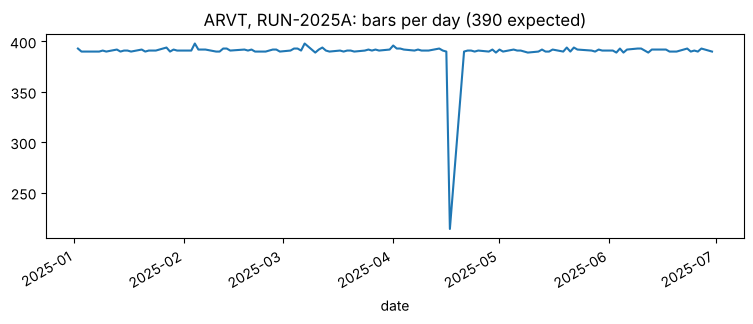

In [16]:
# P21 completeness profile: bars per symbol and day (clean-looking symbol, run A)
d = b[(b.ticker == "ARVT") & (b.run_id == "RUN-2025A") & b.bar_start_local.notna()].groupby("date").size()
print(d.describe().round(1).to_dict(), "| expected 390 (210 on the early close)")
print("bars per run:"); print(bars.groupby("run_id").size())
print("index share of rows:", round((bars.ticker == "INDEX").mean()*100, 2), "%")
print("rows per ticker (skew: late listings / delisting / renames):")
print(bars.groupby("ticker").size().sort_values().head(8))
fig, ax = plt.subplots(figsize=(9, 3)); d.plot(ax=ax); ax.set_title("ARVT, RUN-2025A: bars per day (390 expected)"); plt.show()

* **P21** Bar counts per day wander around 390: some minutes never arrived (gaps) and some were repeated (duplicates).
* **P22** Late-listed (`CELK`, `DOVV`), delisted (`YARL`, last day 2025-04-29) and renamed (`ORBT`/`ORBX`) symbols have fewer rows on purpose: expected bars must follow the listing window.

## 4. Vendor daily file (CSV)

In [17]:
v = R.read_vendor()
print(v.shape, v.isna().sum().sum(), "nulls |", "duplicated key:", v.duplicated(["run_id","date","ticker"]).sum())
print("tickers not in symbols.csv:", sorted(set(v.ticker) - set(sym.ticker)))
print("vendor days per run:", v.groupby("run_id").date.nunique().to_dict(), "| rows per run:", v.groupby("run_id").size().to_dict())
print("OHLC broken in vendor file:", ((v.high < v.low) | (v.open > v.high) | (v.close > v.high) | (v.open < v.low) | (v.close < v.low)).sum())

(10831, 9) 0 nulls | duplicated key: 0
tickers not in symbols.csv: ['INDEX', 'ORBT']
vendor days per run: {'RUN-2025A': 123, 'RUN-2025B': 123, 'RUN-2025C': 123} | rows per run: {'RUN-2025A': 3612, 'RUN-2025B': 3605, 'RUN-2025C': 3614}
OHLC broken in vendor file: 0


In [18]:
# P23/P24 how the vendor's conventions differ from the minute bars (RUN-2025A, simple daily from raw bars)
a = b[(b.run_id == "RUN-2025A") & b.close.notna() & b.bar_start_local.notna() & (b.tod >= "09:30")]
a = a.drop_duplicates(["ticker","bar_start_utc"]).sort_values("bar_start_utc")
dd = a.groupby(["ticker","date"]).agg(open=("open","first"), close=("close","last"), volume=("volume","sum")).reset_index()
vv = v[v.run_id == "RUN-2025A"].assign(date=lambda x: pd.to_datetime(x.date))
m = dd.merge(vv, on=["ticker","date"], suffixes=("","_v"))
for t in ["JORV", "FENM"]:
    x = m[(m.ticker == t)].head(3)
    print(t); print(x[["date","open","open_v","volume","volume_v"]].assign(price_ratio=lambda z: z.open_v/z.open, vol_ratio=lambda z: z.volume_v/z.volume).to_string())

JORV
           date    open  open_v  volume  volume_v  price_ratio  vol_ratio
1577 2025-01-02  455.96  227.98  359533    724314     0.500000   2.014597
1578 2025-01-03  445.23  222.62  367650    736568     0.500011   2.003449
1579 2025-01-06  446.78  223.39  388375    776750     0.500000   2.000000
FENM
          date   open  open_v  volume  volume_v  price_ratio  vol_ratio
967 2025-01-02  65.85   65.85  923979      9240          1.0   0.010000
968 2025-01-03  64.64   64.64  963051      9642          1.0   0.010012
969 2025-01-06  64.16   64.16  919524      9195          1.0   0.010000


* **P23** The vendor's prices for JORV **before the split** are already divided by 2 (and the volume doubled): they are split-adjusted, our raw bars are not. Compare on the same basis.
* **P24** For `FENM` the vendor volume is **1/100** of the minute-bar volume: the vendor counts round lots of 100 shares.
* **P25** After the two conventions above, 49 days still differ with no minute missing: 24 are `RUN-2025B` on 2025-04-17 (the vendor includes the bars after the 13:00 early close that the calendar rejects) and 25 have a vendor close that is 1 to 5 cents away from the last minute's close. The derived bar is the source of truth, so these stay reported as mismatches.
* **P26** `vendor_daily.csv` has a row for the index and one for `ORBT` (old ticker), so the vendor's own ticker must be resolved as of the date, with the same dimension.

## 5. Held out until Milestone 2 (only checked, not used)
`stream_bars.json` has 1,814 items: 1,800 bars, 13 broken JSON strings and one EOS record, and it contains `RUN-TEST`. `regime_labels.csv` is ground truth for 123 days per run and is **never** read by this milestone.

In [19]:
s = json.load(open(RAW / "stream_bars.json"))
import collections; print(collections.Counter(type(x).__name__ for x in s))
print("regime_labels rows:", len(pd.read_csv(RAW / "regime_labels.csv")), "(not used in M1)")

Counter({'dict': 1801, 'str': 13})
regime_labels rows: 369 (not used in M1)
